In [8]:
%pip install --no-cache-dir --force-reinstall \
  "huggingface-hub==0.36.2" \
  "datasets==3.6.0" \
  "transformers==4.48.3" \
  "tokenizers==0.21.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 14.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 58.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 252.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 82.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 591.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 68.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 82.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 801.6/801.6 kB 195.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 807.9/807.9 kB 170.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 76.6 MB/s  0:00:00
  Attempting uninstall: xxhash
    Found existing installation: xxhash 4.0.2
    Uninstalling xxhash-4.0.2:
      Successfully uninstalled xxhash-4.0.2
  Attempting uninstall: urllib3
    Found existing installation: urllib3 2.5.0
    Uni

In [4]:
from transformers import pipeline

qa_pipeline = pipeline(
    "question-answering",
    model="distilbert/distilbert-base-cased-distilled-squad"
)

print("Question Answering model loaded successfully!")

Device set to use cpu


Question Answering model loaded successfully!


In [1]:
import transformers
import datasets
import huggingface_hub

print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Transformers: 4.48.3
Datasets: 3.6.0
Hugging Face Hub: 0.36.2


In [4]:
from datasets import load_dataset

squad = load_dataset(
    "parquet",
    data_files={
        "train": "https://huggingface.co/datasets/rajpurkar/squad/resolve/refs%2Fconvert%2Fparquet/plain_text/train/0000.parquet",
        "validation": "https://huggingface.co/datasets/rajpurkar/squad/resolve/refs%2Fconvert%2Fparquet/plain_text/validation/0000.parquet",
    }
)

print("Dataset loaded successfully!")
print(squad)

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Dataset loaded successfully!
DatasetDict({
    train: Dataset({
        features: ['id', 'title', 'context', 'question', 'answers'],
        num_rows: 87599
    })
    validation: Dataset({
        features: ['id', 'title', 'context', 'question', 'answers'],
        num_rows: 10570
    })
})


In [6]:
# Select one validation example
example = squad["validation"][0]

context = example["context"]
question = example["question"]
correct_answer = example["answers"]["text"][0]

# Reload the model only if the runtime restart cleared it
if "qa_pipeline" not in globals():
    from transformers import pipeline
    qa_pipeline = pipeline(
        "question-answering",
        model="distilbert/distilbert-base-cased-distilled-squad"
    )

# Predict the answer
prediction = qa_pipeline(
    question=question,
    context=context
)

print("QUESTION:")
print(question)

print("\nCONTEXT:")
print(context[:700])

print("\nCORRECT ANSWER:")
print(correct_answer)

print("\nPREDICTED ANSWER:")
print(prediction["answer"])

print("\nCONFIDENCE SCORE:")
print(round(prediction["score"], 4))

Device set to use cpu


QUESTION:
Which NFL team represented the AFC at Super Bowl 50?

CONTEXT:
Super Bowl 50 was an American football game to determine the champion of the National Football League (NFL) for the 2015 season. The American Football Conference (AFC) champion Denver Broncos defeated the National Football Conference (NFC) champion Carolina Panthers 24–10 to earn their third Super Bowl title. The game was played on February 7, 2016, at Levi's Stadium in the San Francisco Bay Area at Santa Clara, California. As this was the 50th Super Bowl, the league emphasized the "golden anniversary" with various gold-themed initiatives, as well as temporarily suspending the tradition of naming each Super Bowl game with Roman numerals (under which the game would have been known as "Super B

CORRECT ANSWER:
Denver Broncos

PREDICTED ANSWER:
Denver Broncos

CONFIDENCE SCORE:
0.6159


In [7]:
import re
import string
from collections import Counter

def normalize_answer(text):
    """Normalize an answer for SQuAD Exact Match and F1."""
    text = text.lower()
    text = "".join(
        char for char in text
        if char not in string.punctuation
    )
    text = re.sub(r"\b(a|an|the)\b", " ", text)
    return " ".join(text.split())


def compute_exact_match(prediction, ground_truth):
    return int(
        normalize_answer(prediction)
        == normalize_answer(ground_truth)
    )


def compute_f1(prediction, ground_truth):
    pred_tokens = normalize_answer(prediction).split()
    truth_tokens = normalize_answer(ground_truth).split()

    common = Counter(pred_tokens) & Counter(truth_tokens)
    num_common = sum(common.values())

    if not pred_tokens or not truth_tokens:
        return float(pred_tokens == truth_tokens)

    if num_common == 0:
        return 0.0

    precision = num_common / len(pred_tokens)
    recall = num_common / len(truth_tokens)

    return 2 * precision * recall / (precision + recall)


# Evaluate on 100 validation examples
sample_size = 100
validation_sample = squad["validation"].select(
    range(sample_size)
)

results = []
exact_matches = []
f1_scores = []

for i, example in enumerate(validation_sample):
    prediction = qa_pipeline(
        question=example["question"],
        context=example["context"]
    )

    predicted_answer = prediction["answer"]
    correct_answers = example["answers"]["text"]

    # SQuAD can contain multiple accepted answers
    em = max(
        compute_exact_match(predicted_answer, answer)
        for answer in correct_answers
    )

    f1 = max(
        compute_f1(predicted_answer, answer)
        for answer in correct_answers
    )

    exact_matches.append(em)
    f1_scores.append(f1)

    results.append({
        "question": example["question"],
        "correct_answer": correct_answers[0],
        "predicted_answer": predicted_answer,
        "exact_match": em,
        "f1_score": f1
    })

    if (i + 1) % 20 == 0:
        print(f"Evaluated {i + 1}/{sample_size} questions")

print("\n--- EVALUATION RESULTS ---")
print(f"Examples evaluated: {sample_size}")
print(f"Exact Match: {sum(exact_matches) / sample_size * 100:.2f}%")
print(f"Average F1 Score: {sum(f1_scores) / sample_size * 100:.2f}%")

Evaluated 20/100 questions
Evaluated 40/100 questions
Evaluated 60/100 questions
Evaluated 80/100 questions
Evaluated 100/100 questions

--- EVALUATION RESULTS ---
Examples evaluated: 100
Exact Match: 84.00%
Average F1 Score: 89.00%


In [8]:
import pandas as pd

results_df = pd.DataFrame(results)

results_df.to_csv(
    "question_answering_results.csv",
    index=False
)

print("Results saved successfully!")
print("Rows:", len(results_df))
display(results_df.head(10))

from google.colab import files
files.download("question_answering_results.csv")

Results saved successfully!
Rows: 100


,question,correct_answer,predicted_answer,exact_match,f1_score
0,Which NFL team represented the AFC at Super Bo...,Denver Broncos,Denver Broncos,1,1.0
1,Which NFL team represented the NFC at Super Bo...,Carolina Panthers,Carolina Panthers,1,1.0
2,Where did Super Bowl 50 take place?,"Santa Clara, California",Levi's Stadium in the San Francisco Bay Area a...,1,1.0
3,Which NFL team won Super Bowl 50?,Denver Broncos,Carolina Panthers,0,0.0
4,What color was used to emphasize the 50th anni...,gold,gold,1,1.0
5,What was the theme of Super Bowl 50?,"""golden anniversary""",golden anniversary,1,1.0
6,What day was the game played on?,"February 7, 2016","February 7, 2016",1,1.0
7,What is the AFC short for?,American Football Conference,American Football Conference,1,1.0
8,What was the theme of Super Bowl 50?,"""golden anniversary""",golden anniversary,1,1.0
9,What does AFC stand for?,American Football Conference,American Football Conference,1,1.0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

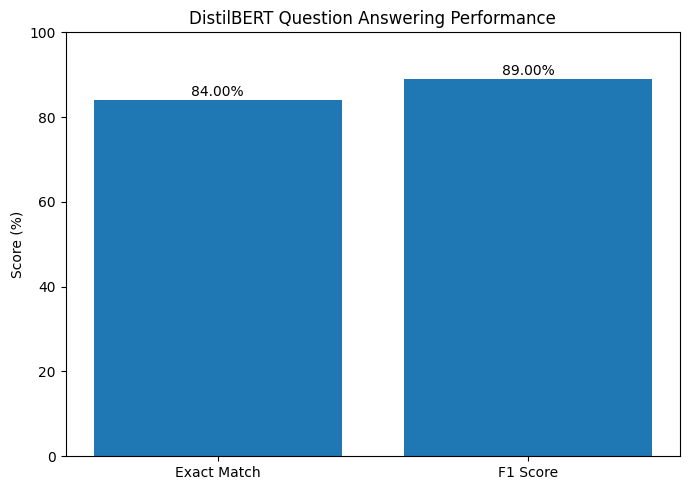

Chart saved as question_answering_metrics.png


In [9]:
import matplotlib.pyplot as plt

metrics = ["Exact Match", "F1 Score"]
scores = [
    sum(exact_matches) / len(exact_matches) * 100,
    sum(f1_scores) / len(f1_scores) * 100
]

plt.figure(figsize=(7, 5))
bars = plt.bar(metrics, scores)

plt.ylim(0, 100)
plt.ylabel("Score (%)")
plt.title("DistilBERT Question Answering Performance")

for bar, score in zip(bars, scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{score:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.savefig("question_answering_metrics.png", dpi=300)
plt.show()

print("Chart saved as question_answering_metrics.png")